In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


In [2]:
POLLUTANT = "pm25"
LAGGED_DAYS = (1, 2, 3)
ROLLING_WINDOWS = (3, 7)
TEST_FRACTION = 0.2

In [3]:
PROCESSED_DIR = Path("../data/processed")
FEATURES_FILE = PROCESSED_DIR / f"features_{POLLUTANT}.parquet"

In [4]:
df = pd.read_parquet(FEATURES_FILE)
df["date"] = pd.to_datetime(df["date"])

In [5]:
lag_cols = [f"{POLLUTANT}_lag_{d}" for d in LAGGED_DAYS]
rolling_cols = [f"{POLLUTANT}_rolling_{w}" for w in ROLLING_WINDOWS]
rolling_std_cols = [f"{POLLUTANT}_rolling_std_{w}" for w in ROLLING_WINDOWS]
calendar_cols = ["month_sin", "month_cos", "dow_sin", "dow_cos"]
weather_cols = [
    col for col in df.columns
    if (col.startswith(("temperature", "relative_humidity", "dew_point",
                        "apparent_temperature", "pressure", "surface_pressure",
                        "precipitation", "rain_sum", "snowfall", "cloud_cover",
                        "shortwave", "direct_radiation", "diffuse_radiation",
                        "global_tilted", "sunshine", "wind", "et0",
                        "weather_code", "snow_depth", "vapour_pressure", "soil_"))
        and col != "wind_category")
]

In [6]:
base_cols = lag_cols + rolling_cols + rolling_std_cols + calendar_cols + weather_cols + ["rain_indicator", "is_weekend"]
required = base_cols + ["date", "station_id", POLLUTANT]

model_df = df.dropna(subset=required).copy().reset_index(drop=True)
model_df = model_df.sort_values("date").reset_index(drop=True)

In [7]:
wind_dummies = pd.get_dummies(model_df["wind_category"], prefix="wind")
X = pd.concat([model_df[base_cols].reset_index(drop=True), wind_dummies.reset_index(drop=True)], axis=1).astype(float)
y = model_df[POLLUTANT].astype(float)

In [8]:

split_idx = int(len(model_df) * (1 - TEST_FRACTION))
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Modelling rows: {len(model_df):,}  ({int((1-TEST_FRACTION)*100)}% train / {int(TEST_FRACTION*100)}% test)")
print(f"Train period: {model_df['date'].iloc[0].date()} .. {model_df['date'].iloc[split_idx-1].date()}")
print(f"Test period : {model_df['date'].iloc[split_idx].date()} .. {model_df['date'].iloc[-1].date()}")


Modelling rows: 1,912  (80% train / 20% test)
Train period: 2018-04-26 .. 2024-07-19
Test period : 2024-07-19 .. 2025-12-31


In [9]:
def evaluate_regression(y_true, y_pred):
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred)),
    }

In [10]:
baseline_mae = mean_absolute_error(y_test, model_df[POLLUTANT + "_lag_1"].iloc[split_idx:])
baseline_rmse = float(np.sqrt(mean_squared_error(y_test, model_df[POLLUTANT + "_lag_1"].iloc[split_idx:])))
baseline_r2 = float(r2_score(y_test, model_df[POLLUTANT + "_lag_1"].iloc[split_idx:]))

In [11]:
models = {
    "LinearRegression": LinearRegression(),
    "RandomForest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(random_state=42),
}

In [12]:
results = {}
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results[name] = evaluate_regression(y_test, pred)
    predictions[name] = pred

results["Persistence(lag1)"] = {"RMSE": baseline_rmse, "MAE": baseline_mae, "R2": baseline_r2}
predictions["Persistence(lag1)"] = model_df[POLLUTANT + "_lag_1"].iloc[split_idx:].to_numpy()

In [13]:

results_df = pd.DataFrame(results).T
results_df = results_df.reindex(results_df["RMSE"].sort_values().index)
display(results_df.round(3))


,RMSE,MAE,R2
LinearRegression,13.616,8.925,0.734
Persistence(lag1),14.583,8.665,0.695
RandomForest,15.162,10.634,0.670
GradientBoosting,18.051,13.075,0.533


In [14]:
comparison = pd.DataFrame({"y_test": y_test.reset_index(drop=True)})
for name, pred in predictions.items():
    comparison[name] = pred

comparison["date"] = model_df["date"].iloc[split_idx:].reset_index(drop=True)
comparison["station_id"] = model_df["station_id"].iloc[split_idx:].reset_index(drop=True)

best_model = results_df["RMSE"].idxmin()
print(f"Best regression model: {best_model}")
print(f"Improvement over persistence in RMSE: {((baseline_rmse - results_df.loc[best_model, 'RMSE']) / baseline_rmse * 100):.1f}%")
display(comparison.head(10))


Best regression model: LinearRegression
Improvement over persistence in RMSE: 6.6%


,y_test,LinearRegression,RandomForest,GradientBoosting,Persistence(lag1),date,station_id
0,16.494167,18.134846,15.506177,15.903025,17.212500,2024-07-19,2996
1,11.604167,16.004359,14.608060,15.008323,14.012500,2024-07-19,2978
2,18.650000,17.575804,22.025742,21.234306,17.666667,2024-07-20,2976
3,15.933333,15.688569,20.311288,19.254576,14.837500,2024-07-20,2919
4,18.037500,16.837399,18.203704,19.254576,16.494167,2024-07-20,2996
5,15.137500,15.760371,21.878258,19.254576,14.688333,2024-07-20,2977
6,14.891667,14.121377,21.795865,27.234731,11.604167,2024-07-20,2978
7,15.657500,17.064670,22.422209,20.824684,18.037500,2024-07-21,2996
8,14.500000,14.817956,21.015047,18.844953,14.891667,2024-07-21,2978
9,17.308333,17.751579,23.009060,20.824684,18.650000,2024-07-21,2976


In [15]:
best_fit_model = models[best_model]

if hasattr(best_fit_model, "feature_importances_"):
    importance = best_fit_model.feature_importances_
else:
    importance = np.abs(best_fit_model.coef_)

imp_df = pd.DataFrame({"feature": X.columns, "importance": importance}).sort_values("importance", ascending=False)
display(imp_df.head(15))

,feature,importance
44,snow_depth_mean,52.652229
52,soil_moisture_28_to_100cm_mean,44.273049
18,apparent_temperature_mean,7.016671
50,soil_moisture_0_to_7cm_mean,6.778709
51,soil_moisture_7_to_28cm_mean,6.531598
35,wind_speed_10m_mean,6.114802
53,soil_moisture_100_to_255cm_mean,5.721430
42,et0_fao_evapotranspiration_sum,4.626169
11,temperature_2m_mean,4.489505
17,dew_point_2m_mean,4.444955


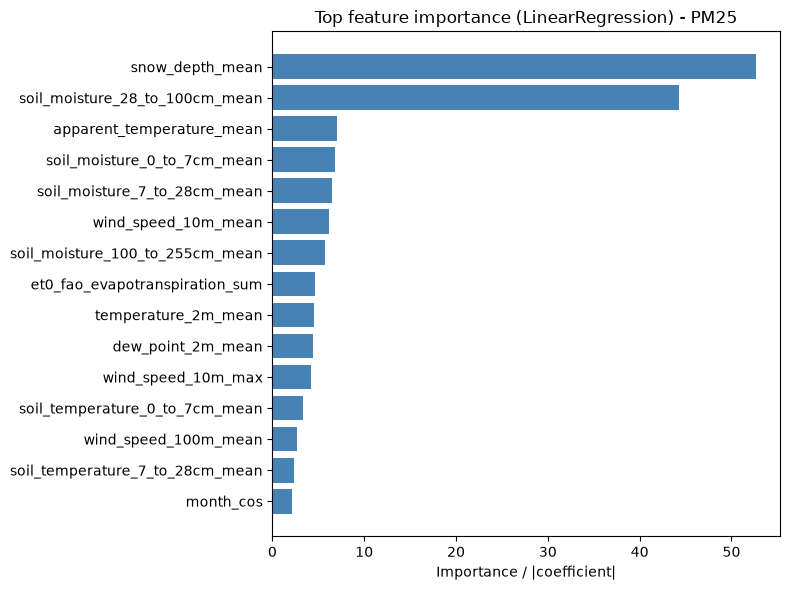

In [16]:
plt.figure(figsize=(8, 6))
plot_df = imp_df.head(15).iloc[::-1]
plt.barh(plot_df["feature"], plot_df["importance"], color="steelblue")
plt.xlabel("Importance / |coefficient|")
plt.title(f"Top feature importance ({best_model}) - {POLLUTANT.upper()}")
plt.tight_layout()
plt.show()

In [17]:
feature_names = list(X.columns)

FACTOR_GROUPS = {
    "Previous pollution (lag)": [f"{POLLUTANT}_lag_{d}" for d in LAGGED_DAYS],
    "Previous pollution (rolling)": [f"{POLLUTANT}_rolling_{w}" for w in ROLLING_WINDOWS] + [f"{POLLUTANT}_rolling_std_{w}" for w in ROLLING_WINDOWS],
    "Temperature": [c for c in feature_names if "temperature" in c or "dew_point" in c],
    "Humidity": [c for c in feature_names if "humidity" in c or "vapour_pressure" in c],
    "Wind": [c for c in feature_names if "wind" in c and "category" not in c] + [c for c in feature_names if c.startswith("wind_")],
    "Precipitation": [c for c in feature_names if "precip" in c or "rain" in c or "snowfall" in c or "snow_depth" in c],
    "Pressure": [c for c in feature_names if "pressure" in c],
    "Clouds & radiation": [c for c in feature_names if "cloud" in c or "radiation" in c or "sunshine" in c or "et0" in c],
    "Season / calendar": [c for c in feature_names if "month" in c or "dow" in c or "weekend" in c],
    "Soil": [c for c in feature_names if c.startswith("soil")],
    "Wind category": [c for c in feature_names if c.startswith("wind_weak") or c.startswith("wind_moderate") or c.startswith("wind_strong")],
    "Weather code": [c for c in feature_names if "weather_code" in c],
}

In [18]:
factor_importance = []
for factor, cols in FACTOR_GROUPS.items():
    present = [c for c in cols if c in feature_names]
    if not present:
        continue
    vals = [importance[list(feature_names).index(c)] for c in present]
    factor_importance.append({
        "factor": factor,
        "n_features": len(present),
        "importance_max": float(np.max(vals)),
        "importance_mean": float(np.mean(vals)),
    })

factor_df = pd.DataFrame(factor_importance).sort_values("importance_mean", ascending=False)
display(factor_df.round(4))

,factor,n_features,importance_max,importance_mean
5,Precipitation,5,52.6522,11.0398
9,Soil,8,44.2730,8.6524
2,Temperature,9,7.0167,2.5221
4,Wind,20,6.1148,1.8293
8,Season / calendar,5,2.1557,1.1533
10,Wind category,3,1.2151,0.8101
7,Clouds & radiation,9,4.6262,0.6384
3,Humidity,4,1.7122,0.6379
6,Pressure,5,1.7122,0.5164
0,Previous pollution (lag),3,0.4928,0.2269


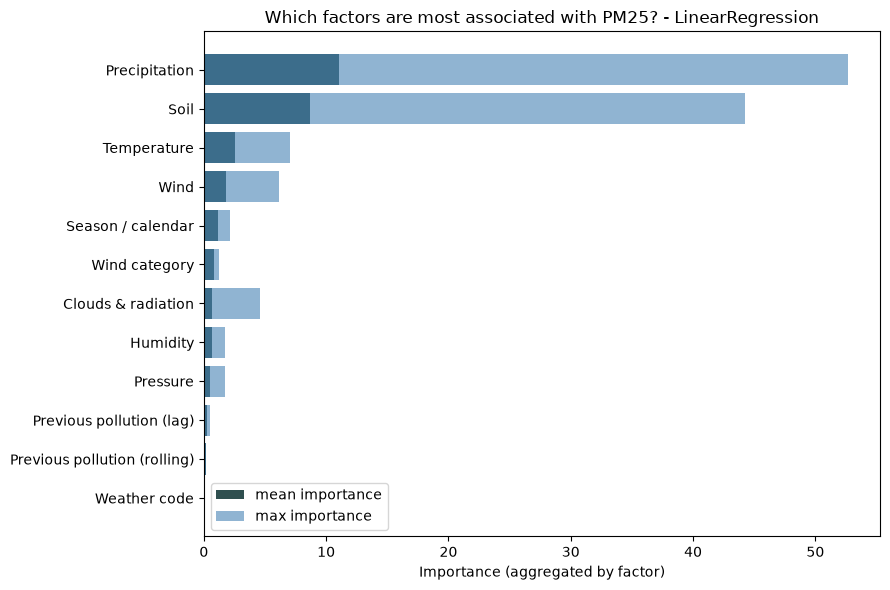

In [19]:
plt.figure(figsize=(9, 6))
plot_df = factor_df.iloc[::-1]
plt.barh(plot_df["factor"], plot_df["importance_mean"], color="darkslategray", label="mean importance")
plt.barh(plot_df["factor"], plot_df["importance_max"], color="steelblue", alpha=0.6, label="max importance")
plt.xlabel("Importance (aggregated by factor)")
plt.title(f"Which factors are most associated with {POLLUTANT.upper()}? - {best_model}")
plt.legend()
plt.tight_layout()
plt.show()


In [21]:
METRICS_OUT = PROCESSED_DIR / f"regression_metrics_{POLLUTANT}.parquet"
PRED_OUT = PROCESSED_DIR / f"regression_predictions_{POLLUTANT}.parquet"

In [22]:
results_df.to_parquet(METRICS_OUT)
comparison.to_parquet(PRED_OUT, index=False)
print(f"Saved: {METRICS_OUT.name}")
print(f"Saved: {PRED_OUT.name}")


Saved: regression_metrics_pm25.parquet
Saved: regression_predictions_pm25.parquet
